# Workshop 10: DLT Vehicle Registration Forecasting

ข้อมูลต้นฉบับ: `DLT_First_Registration_Monthly_Original_Combined.csv` จากกรมการขนส่งทางบก ทำตามสไลด์ `DLT_Vehicle_Forecasting.pptx` หน้า 67–74 และรายการส่งหน้า 50 เปรียบเทียบ 5 วิธีด้วยชุดทดสอบเดียวกัน เลือกจาก MAE จริง แล้วพยากรณ์ล่วงหน้า 1 เดือน

**วิธีรันซ้ำ:** ติดตั้ง `requirements.txt` ใน Python 3.11 เปิด notebook ในโฟลเดอร์นี้ และเลือก Restart Kernel / Run All โดยมีไฟล์ต้นฉบับกับ `forecasting.py` อยู่ด้วย หรือรัน `python build_notebook.py` เพื่อสร้างและรัน notebook ใหม่ใน kernel ของ Python ที่ใช้รันคำสั่ง CSV `.xls` ของอาจารย์เก็บไว้เป็นตัวอย่างเท่านั้นและไม่ใช่ input ของการคำนวณ

**การทดสอบ:** โมเดลเรียนรู้ครั้งเดียวจาก Apr 2024–Jun 2025 และทำนายทีละหนึ่งเดือน ใน Jul 2025–Jan 2026 โดยใช้ยอดจริงของเดือนก่อนที่ทราบแล้วเป็น Lag จึงไม่ใช่การพยากรณ์หลายเดือนพร้อมกันจากจุดเริ่มต้นเดียว

## 1. Load and verify raw data
ตรวจขนาด คอลัมน์ ยอดรวม และบันทึกเวอร์ชันที่ใช้จริง

In [1]:
from pathlib import Path
import hashlib, json, platform
import pandas as pd
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Image, FileLink
from forecasting import create_charts, write_outputs

FEATURES = ['Lag1', 'Lag2', 'Lag3']
RAW_NAME = 'DLT_First_Registration_Monthly_Original_Combined.csv'
folder = Path.cwd()
if not (folder / RAW_NAME).exists():
    folder = folder / 'Workshop 10 Deployment'
assert (folder / RAW_NAME).exists(), 'Place the notebook next to the source CSV'
raw = pd.read_csv(folder / RAW_NAME, encoding='utf-8-sig')
assert raw.shape == (68398, 9)
print('Raw shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Versions:', platform.python_version(), pd.__version__, np.__version__, sklearn.__version__)
print('SHA256:', hashlib.sha256((folder / RAW_NAME).read_bytes()).hexdigest())
display(raw.head())

Raw shape: (68398, 9)
Columns: ['ปี พ.ศ.', 'เดือน', 'ประเภทรถ', 'ยี่ห้อ', 'รุ่น', 'จำนวน', 'Source_Year_BE', 'Source_Month', 'Source_File']
Versions: 3.11.9 2.3.3 2.3.4 1.7.2
SHA256: 9fe035b983666fcd021804c5fc1baaff14cd381d5ae1714527cf5ef2ea856f5d


,ปี พ.ศ.,เดือน,ประเภทรถ,ยี่ห้อ,รุ่น,จำนวน,Source_Year_BE,Source_Month,Source_File
0,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A4 AV 45 TFSI q S line BE,1,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
1,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 CP 40 TFSI S line,15,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
2,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 CP 45 TFSI q S line BE,8,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
3,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 SB 40 TFSI S line,22,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv
4,2565,มกราคม,รถยนต์นั่งส่วนบุคคลไม่เกิน 7 คน,AUDI,A5 SB 45 TFSI q S line BE,4,2565,1,2565_01_sttt_car_new_reg_mm_2565_01.csv


## 2. Aggregate monthly and check gaps
ใช้ Source_Year_BE ลบ 543 เพื่อสร้างปี ค.ศ. และรวมจำนวนพร้อมนับ records ตรวจทุกเดือนระหว่างเดือนแรกกับเดือนสุดท้าย ห้ามเติมช่องว่างโดยเดา

In [2]:
def aggregate_monthly(raw):
    """Sum registrations and count source records, using source period fields."""
    required = ["Source_Year_BE", "Source_Month", "จำนวน"]
    if not set(required).issubset(raw.columns):
        raise ValueError("Missing required source columns")
    data = raw.copy()
    for column in required:
        data[column] = pd.to_numeric(data[column], errors="raise")
    if data[required].isna().any().any() or (data["จำนวน"] < 0).any():
        raise ValueError("Null source period/count or negative registrations")
    monthly = data.groupby(required[:2], as_index=False).agg(
        TotalRegistrations=("จำนวน", "sum"), Records=("จำนวน", "size")
    ).sort_values(required[:2]).reset_index(drop=True)
    monthly["Date"] = pd.to_datetime(dict(
        year=monthly.Source_Year_BE - 543, month=monthly.Source_Month, day=1
    ))
    return monthly

def missing_months(monthly):
    complete = pd.date_range(monthly.Date.min(), monthly.Date.max(), freq="MS")
    return complete.difference(monthly.Date).tolist()

monthly = aggregate_monthly(raw)
gaps = missing_months(monthly)
print('Monthly rows:', len(monthly))
print('Missing months:', [date.strftime('%Y-%m-%d') for date in gaps])
assert len(monthly) == 49
assert gaps == [pd.Timestamp('2023-12-01')]
assert monthly.TotalRegistrations.sum() == pd.to_numeric(raw['จำนวน']).sum()
partial = monthly[monthly.Date == '2026-02-01']
assert partial.Records.iloc[0] == 6 and partial.TotalRegistrations.iloc[0] == 18
display(monthly.head())
display(partial)

Monthly rows: 49
Missing months: ['2023-12-01']


,Source_Year_BE,Source_Month,TotalRegistrations,Records,Date
0,2565,1,227414,1360,2022-01-01
1,2565,2,230805,1423,2022-02-01
2,2565,3,254072,1522,2022-03-01
3,2565,4,194066,1336,2022-04-01
4,2565,5,249154,1436,2022-05-01


,Source_Year_BE,Source_Month,TotalRegistrations,Records,Date
48,2569,2,18,6,2026-02-01


## 3. Choose complete months, create lags, split chronologically
เลือก Jan 2024–Jan 2026 จำนวน 25 เดือน สร้าง Lag1–Lag3 จากอดีตเท่านั้น เหลือ 22 แถว แบ่งตามตำแหน่งเป็น 15/7 ห้าม shuffle เดือน February 2026 ไม่ได้เป็น actual ที่สมบูรณ์จึงไม่ใช้ฝึกหรือทดสอบ

In [3]:
def prepare_model_data(monthly):
    source = monthly[monthly.Date.between("2024-01-01", "2026-01-01")].copy()
    source = source.sort_values("Date").reset_index(drop=True)
    expected = pd.date_range("2024-01-01", "2026-01-01", freq="MS")
    if source.Date.tolist() != expected.tolist():
        raise ValueError("Model period must contain 25 continuous complete months")
    modeling = source[["Date", "TotalRegistrations"]].copy()
    for lag in range(1, 4):
        modeling[f"Lag{lag}"] = modeling.TotalRegistrations.shift(lag)
    modeling = modeling.dropna().reset_index(drop=True)
    split_index = int(len(modeling) * 0.70)
    train = modeling.iloc[:split_index].copy()
    test = modeling.iloc[split_index:].copy()
    return source, modeling, train, test

forecast_data, model_data, train, test = prepare_model_data(monthly)
assert [len(forecast_data), len(model_data), len(train), len(test)] == [25, 22, 15, 7]
assert train.Date.max() < test.Date.min()
print('Source:', forecast_data.Date.min(), 'to', forecast_data.Date.max(), len(forecast_data))
print('Train:', train.Date.min(), 'to', train.Date.max(), len(train))
print('Test:', test.Date.min(), 'to', test.Date.max(), len(test))
display(model_data.head())
display(test)

Source: 2024-01-01 00:00:00 to 2026-01-01 00:00:00 25
Train: 2024-04-01 00:00:00 to 2025-06-01 00:00:00 15
Test: 2025-07-01 00:00:00 to 2026-01-01 00:00:00 7


,Date,TotalRegistrations,Lag1,Lag2,Lag3
0,2024-04-01,181314,214311.0,208918.0,239866.0
1,2024-05-01,227170,181314.0,214311.0,208918.0
2,2024-06-01,211518,227170.0,181314.0,214311.0
3,2024-07-01,200405,211518.0,227170.0,181314.0
4,2024-08-01,187264,200405.0,211518.0,227170.0


,Date,TotalRegistrations,Lag1,Lag2,Lag3
15,2025-07-01,201436,215312.0,227343.0,185014.0
16,2025-08-01,182449,201436.0,215312.0,227343.0
17,2025-09-01,188713,182449.0,201436.0,215312.0
18,2025-10-01,185344,188713.0,182449.0,201436.0
19,2025-11-01,177066,185344.0,188713.0,182449.0
20,2025-12-01,184093,177066.0,185344.0,188713.0
21,2026-01-01,250212,184093.0,177066.0,185344.0


## 4. Train and compare five methods
Naive ใช้ Lag1 โดยไม่ต้อง fit Ridge alpha=1.0, Random Forest 100 trees/depth 3/seed 42, Gradient Boosting 100 rounds/learning rate 0.05/depth 2/seed 42 ตามสไลด์ 70 MAE และ RMSE วัดจำนวนคันที่ผิดพลาด R² ไม่ใช่เปอร์เซ็นต์ความแม่นยำ

In [4]:
def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42
        ),
    }

def evaluate_models(models, train, test):
    predictions = {"Naive Forecast": test.Lag1.to_numpy()}
    for name, model in models.items():
        model.fit(train[FEATURES], train.TotalRegistrations)
        predictions[name] = model.predict(test[FEATURES])
    results = []
    for name, predicted in predictions.items():
        results.append({
            "Model": name,
            "MAE": float(mean_absolute_error(test.TotalRegistrations, predicted)),
            "RMSE": float(np.sqrt(mean_squared_error(test.TotalRegistrations, predicted))),
            "R2": float(r2_score(test.TotalRegistrations, predicted)),
        })
    comparison = pd.DataFrame(results).sort_values("MAE", kind="stable").reset_index(drop=True)
    comparison["SelectedModel"] = comparison.Model == comparison.iloc[0].Model
    return comparison, predictions

models = make_models()
comparison, predictions = evaluate_models(models, train, test)
best_model_name = comparison.iloc[0].Model
assert comparison.SelectedModel.sum() == 1
print('Selected by lowest MAE:', best_model_name)
display(comparison)

Selected by lowest MAE: Random Forest


,Model,MAE,RMSE,R2,SelectedModel
0,Random Forest,14208.358697,20836.620067,0.203996,True
1,Naive Forecast,17702.857143,26974.229967,-0.334009,False
2,Gradient Boosting,17781.420222,26939.841449,-0.330610,False
3,Ridge Regression,18002.434704,23781.441049,-0.036900,False
4,Linear Regression,18002.434704,23781.441049,-0.036900,False


## 5. Retrain selected model and predict February 2026
หลังจบการประเมินจึงฝึกใหม่ด้วย 22 observations ใช้ Jan 2026 / Dec 2025 / Nov 2025 เป็น Lag1–Lag3 หาก Naive ชนะจะใช้เดือนล่าสุดโดยไม่เรียก fit โมเดล

In [5]:
def forecast_next_month(best_name, models, modeling, source):
    if best_name == "Naive Forecast":
        return float(source.TotalRegistrations.iloc[-1]), None
    final_model = clone(models[best_name])
    final_model.fit(modeling[FEATURES], modeling.TotalRegistrations)
    latest = source.TotalRegistrations.iloc[-3:]
    future_input = pd.DataFrame({
        "Lag1": [latest.iloc[-1]], "Lag2": [latest.iloc[-2]], "Lag3": [latest.iloc[-3]]
    })
    return float(final_model.predict(future_input)[0]), final_model

future_prediction, final_model = forecast_next_month(best_model_name, models, model_data, forecast_data)
forecast_month = forecast_data.Date.max() + pd.DateOffset(months=1)
future_input = pd.DataFrame({f'Lag{i}': [forecast_data.TotalRegistrations.iloc[-i]] for i in range(1, 4)})
display(future_input)
print('Forecast month:', forecast_month.strftime('%Y-%m'))
print('Unrounded forecast:', future_prediction)
print('Forecast vehicles:', round(future_prediction))

,Lag1,Lag2,Lag3
0,250212,184093,177066


Forecast month: 2026-02
Unrounded forecast: 204585.51711796538
Forecast vehicles: 204586


## 6. Export the required Power BI CSVs and verify saved files
History 18 แถว / Test 7 แถว / Future 1 แถว เว้น Actual ของ Future ว่าง ไม่ใช้ 0 และไม่เอา 18 คันจากข้อมูลไม่ครบมาเป็น Ground Truth ชื่อโมเดลและ prediction ทุกส่วนใช้โมเดลที่ได้รับเลือกจริง

In [6]:
powerbi, verification = write_outputs(folder, raw, monthly, forecast_data, model_data, train, test, comparison, predictions, future_prediction)
comparison_path = folder / 'DLT_Model_Comparison_PowerBI.csv'
forecast_path = folder / 'DLT_Vehicle_Forecast_PowerBI.csv'
saved_comparison = pd.read_csv(comparison_path, encoding='utf-8-sig')
saved_forecast = pd.read_csv(forecast_path, encoding='utf-8-sig', parse_dates=['Date'])
assert saved_comparison.columns.tolist() == ['Model','MAE','RMSE','R2','SelectedModel']
assert saved_forecast.columns.tolist() == ['Date','ActualRegistrations','ForecastRegistrations','DatasetSegment','Model']
assert saved_forecast.DatasetSegment.value_counts().to_dict() == {'History':18,'Test':7,'Future':1}
assert saved_forecast[saved_forecast.DatasetSegment == 'Future'].ActualRegistrations.isna().all()
assert saved_forecast.Model.eq(best_model_name).all()
print('Saved:', comparison_path.resolve(), comparison_path.exists())
print('Saved:', forecast_path.resolve(), forecast_path.exists())
display(saved_forecast.tail(8))
display(FileLink(str(comparison_path)))
display(FileLink(str(forecast_path)))

Saved: D:\Github\BI 2026\Workshop 10 Deployment\DLT_Model_Comparison_PowerBI.csv True
Saved: D:\Github\BI 2026\Workshop 10 Deployment\DLT_Vehicle_Forecast_PowerBI.csv True


,Date,ActualRegistrations,ForecastRegistrations,DatasetSegment,Model
18,2025-07-01,201436.0,204423.060171,Test,Random Forest
19,2025-08-01,182449.0,196084.787651,Test,Random Forest
20,2025-09-01,188713.0,188309.537667,Test,Random Forest
21,2025-10-01,185344.0,193992.131810,Test,Random Forest
22,2025-11-01,177066.0,188837.918802,Test,Random Forest
23,2025-12-01,184093.0,196284.034548,Test,Random Forest
24,2026-01-01,250212.0,200390.884437,Test,Random Forest
25,2026-02-01,NaN,204586.000000,Future,Random Forest


D:\Github\BI 2026\Workshop 10 Deployment\DLT_Model_Comparison_PowerBI.csv

D:\Github\BI 2026\Workshop 10 Deployment\DLT_Vehicle_Forecast_PowerBI.csv

## 7. Review model comparison and actual vs forecast
MAE เรียงน้อยไปมาก เส้น Actual ใช้ Date จริง ส่วน forecast แสดง Test และแยก Future ที่ไม่มี actual ภาพรวมนี้เป็นภาพตรวจผลการคำนวณ งาน Power BI .pbix ต้องเปิดและตรวจแยกต่างหาก

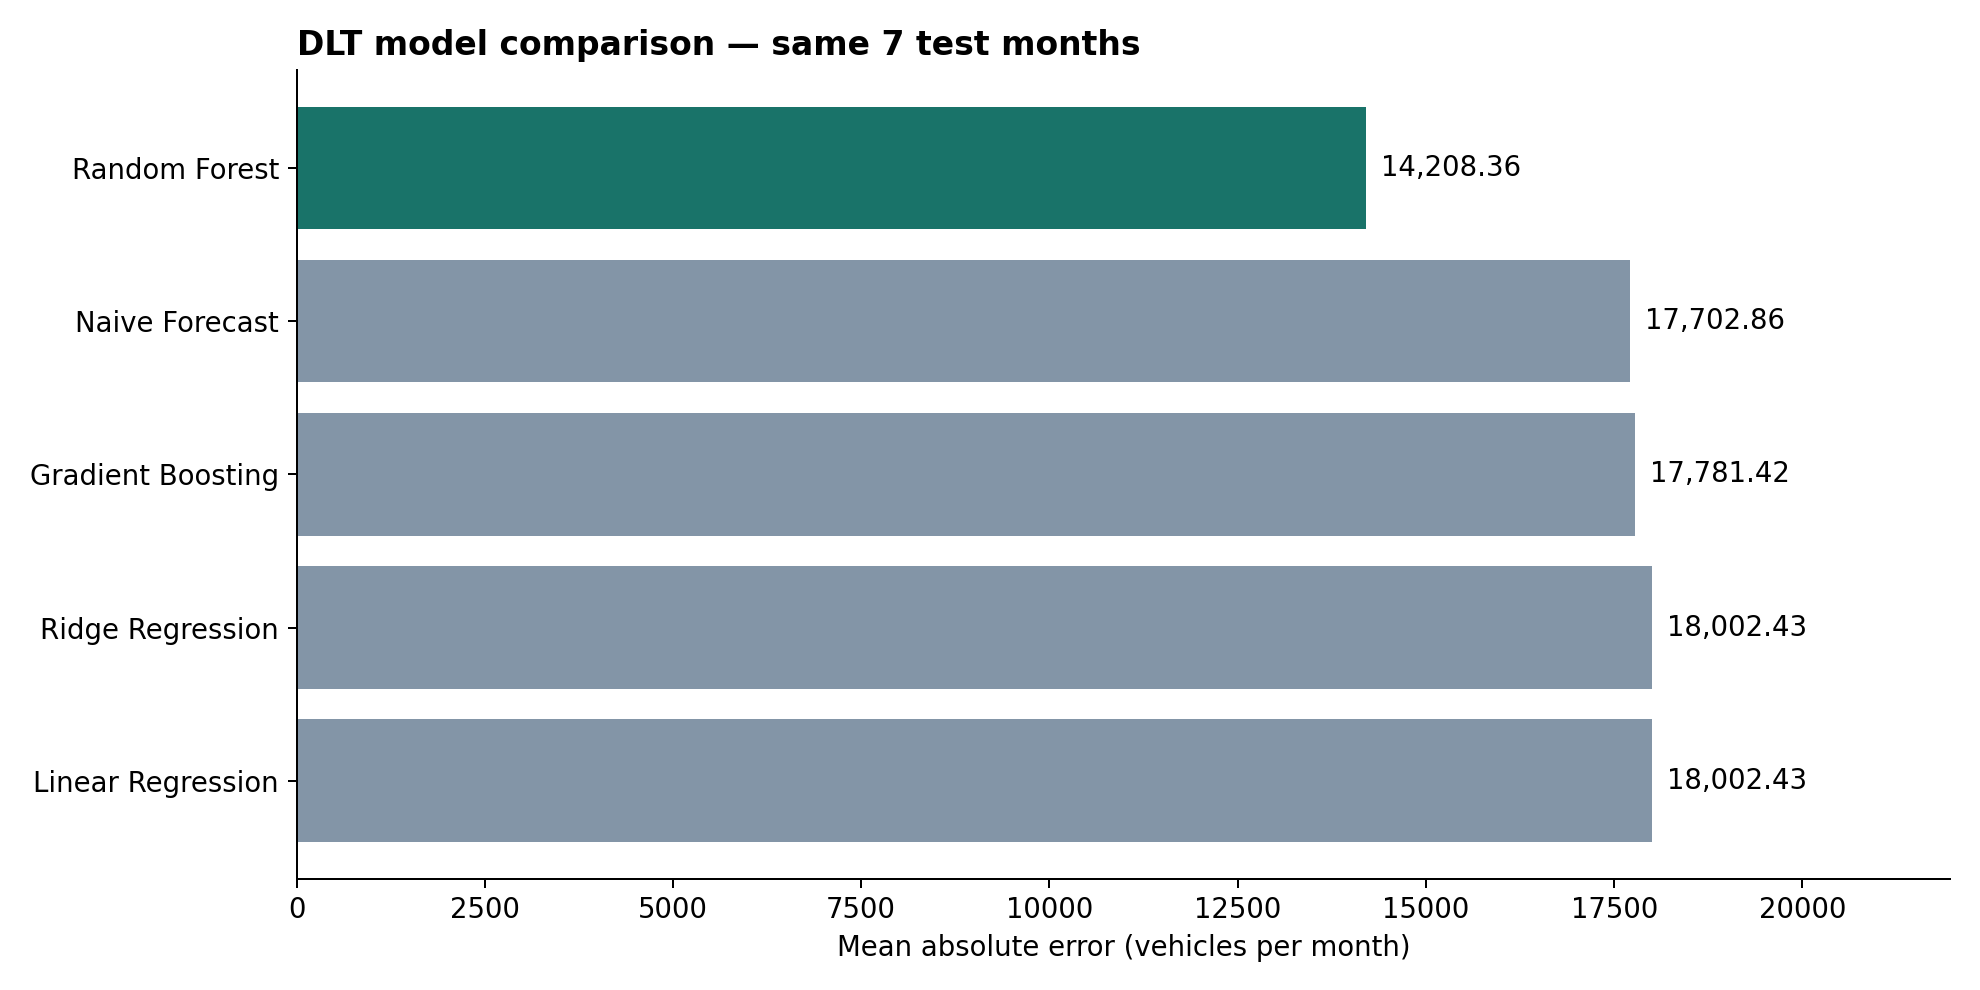

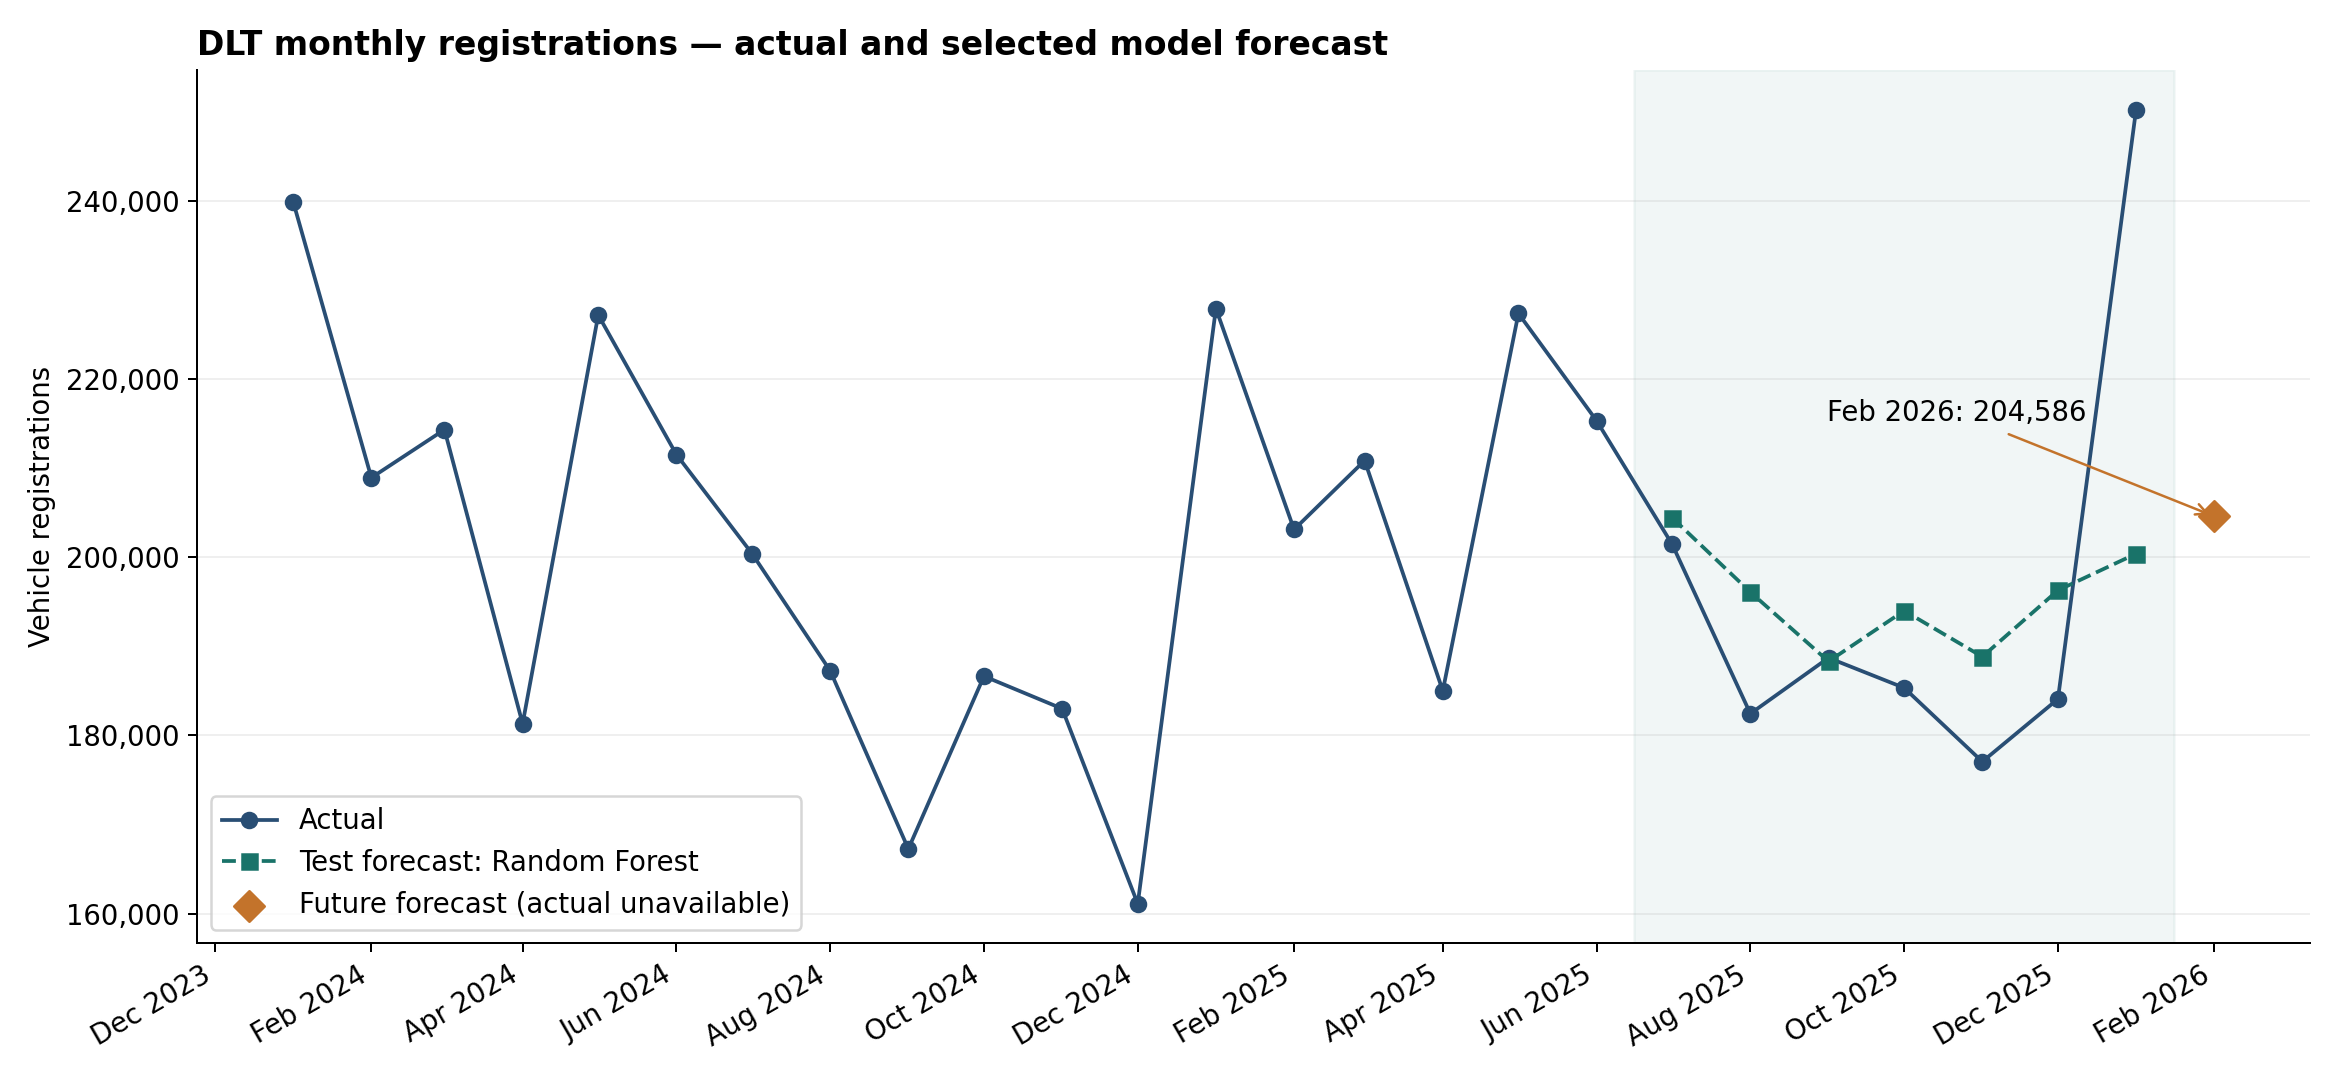

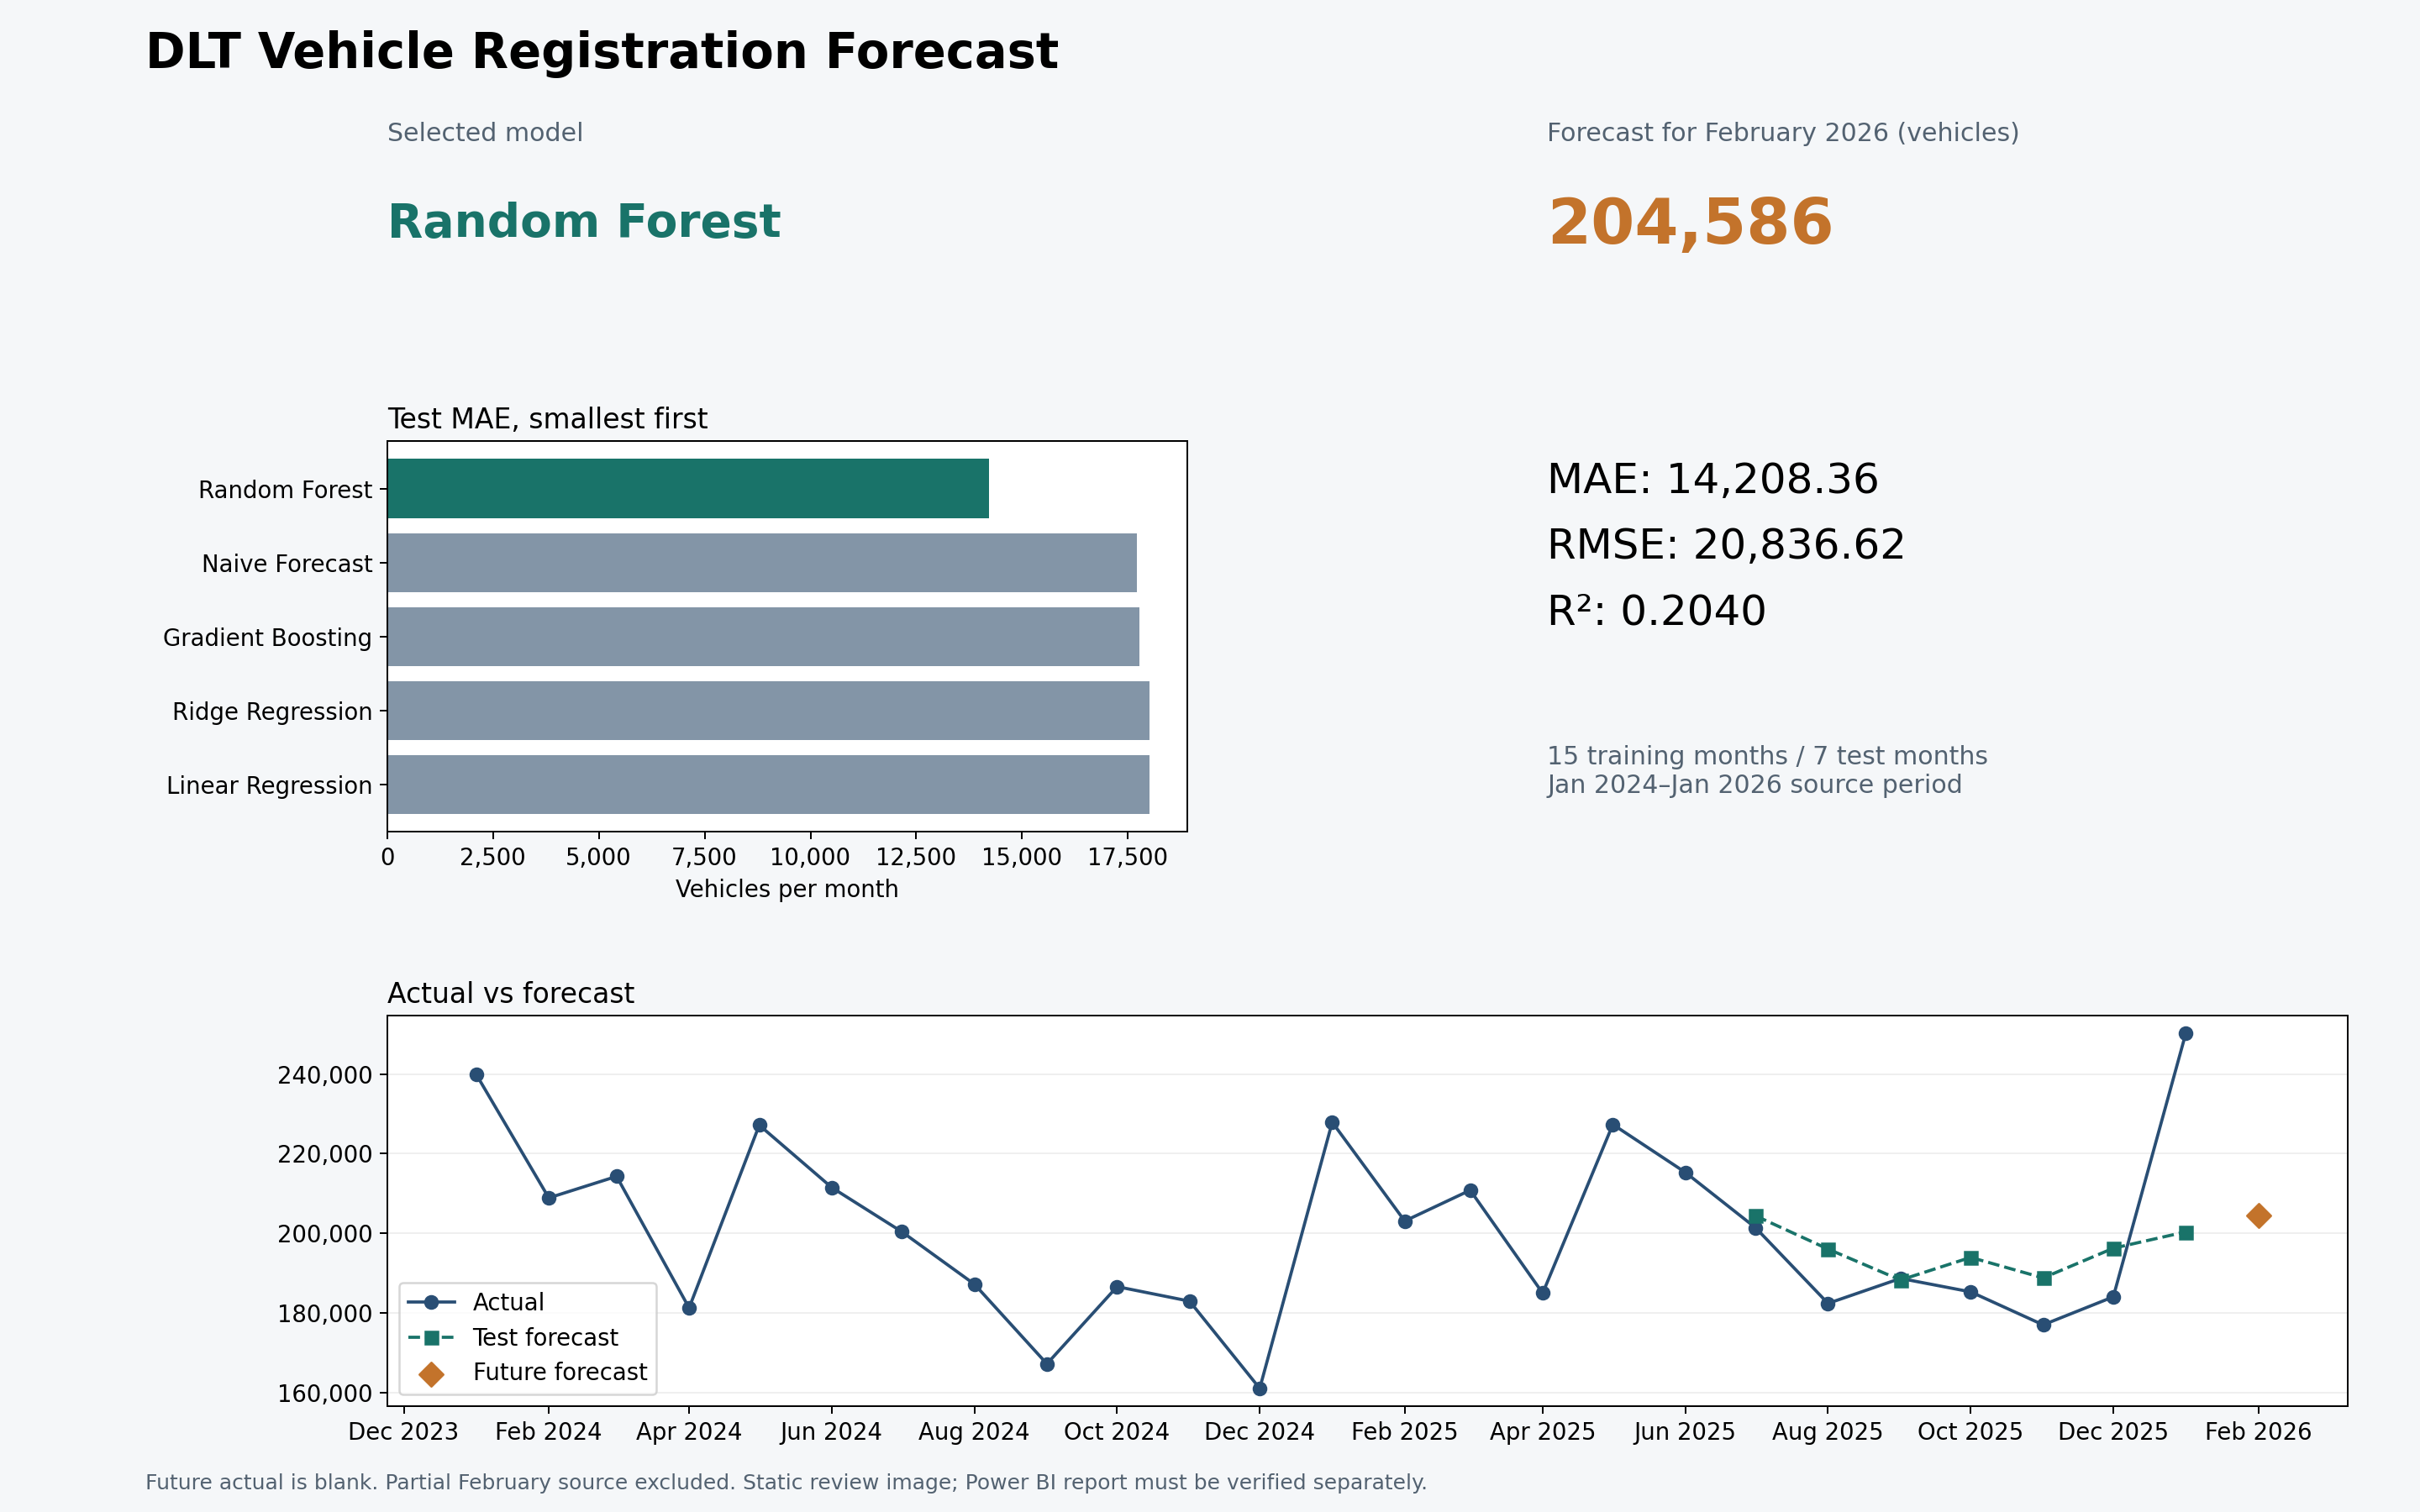

In [7]:
display(Image(filename=str(folder / 'model_comparison.png')))
display(Image(filename=str(folder / 'actual_vs_forecast.png')))
display(Image(filename=str(folder / 'Workshop10_Forecast_Dashboard.png')))

## 8. Compare the observed result with the slide example
ค่าตัวอย่างเป็น benchmark สำหรับตรวจสอบเท่านั้น ไม่ได้กำหนดผลที่โมเดลต้องคืน ถ้าไม่เท่าต้องรายงานผลจริงและตรวจช่วงข้อมูล พารามิเตอร์ seed และเวอร์ชัน

In [8]:
rf = comparison[comparison.Model == 'Random Forest'].iloc[0]
benchmark = verification['slide_expected_rf']
print('RF MAE difference from slide:', rf.MAE - benchmark['MAE'])
print('RF RMSE difference from slide:', rf.RMSE - benchmark['RMSE'])
print('RF R2 difference from slide:', rf.R2 - benchmark['R2'])
print('Rounded forecast difference from slide:', round(future_prediction) - benchmark['forecast_rounded'])
print('The computed values reproduce the slide benchmark.' if np.allclose([rf.MAE,rf.RMSE,rf.R2],[benchmark['MAE'],benchmark['RMSE'],benchmark['R2']]) and round(future_prediction) == benchmark['forecast_rounded'] else 'The computed results differ; preserve and explain the measured results.')

RF MAE difference from slide: 0.0
RF RMSE difference from slide: 0.0
RF R2 difference from slide: 0.0
Rounded forecast difference from slide: 0
The computed values reproduce the slide benchmark.


## 9. สรุปผลหนึ่งย่อหน้าและข้อจำกัด
ข้อจำกัดการทดสอบช่วงเดียวและการใช้ test เลือกโมเดล ควรมี rolling-origin validation และข้อมูลภายนอกเพิ่มก่อนใช้งานจริง

In [9]:
print((folder / 'summary.txt').read_text(encoding='utf-8'))

จากข้อมูลรถจดทะเบียนครั้งแรกของกรมการขนส่งทางบก 68,398 แถว 9 คอลัมน์ เมื่อรวมเป็นรายเดือนได้ 49 เดือน พบเดือนธันวาคม 2566 ขาดหาย และข้อมูลกุมภาพันธ์ 2569 มีเพียง 6 รายการรวม 18 คัน จึงเลือกข้อมูลที่ต่อเนื่องตั้งแต่มกราคม 2567 ถึงมกราคม 2569 จำนวน 25 เดือน สร้าง Lag1–Lag3 เหลือ 22 ตัวอย่าง และแบ่งตามเวลาเป็นชุดฝึก 15 เดือนและชุดทดสอบ 7 เดือนโดยไม่สุ่ม เมื่อเปรียบเทียบ 5 วิธี Random Forest ให้ MAE ต่ำที่สุดเท่ากับ 14,208.36 คันต่อเดือน RMSE 20,836.62 คัน และ R² 0.2040 จึงเลือกและฝึกใหม่ด้วยข้อมูลแบบจำลองทั้งหมด เพื่อพยากรณ์กุมภาพันธ์ 2569 ได้ 204,586 คัน ซึ่งเป็นค่าพยากรณ์และเว้น Actual ของเดือนอนาคตว่าง การทดสอบเป็นการพยากรณ์ล่วงหน้าทีละหนึ่งเดือนโดยใช้ยอดจริงเดือนก่อนที่ทราบแล้วเป็น Lag ข้อจำกัดคือข้อมูลแบบจำลองและชุดทดสอบมีจำนวนน้อย ใช้เพียงข้อมูลย้อนหลัง 3 เดือน ไม่มีปัจจัยภายนอก และทดสอบเพียงช่วงเดียว การเลือกโมเดลจากชุดทดสอบเดียวกันยังไม่มีชุดตรวจสอบอิสระ R² จึงต้องอ่านเป็นการอธิบายความแปรปรวน ไม่ใช่เปอร์เซ็นต์ความแม่นยำ ผลเหมาะกับการเรียนรู้และควรตรวจสอบเพิ่มก่อนใช้งานจริง

